In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
# If launched from a generic working directory in a hosted environment, use the
# mounted upload folder only when the project files are not present in the current root.
if ROOT == Path("/") and Path("/mnt/data/payroll_monthly_features.csv").exists():
    ROOT = Path("/mnt/data")

DATA_DIR = ROOT / "data"
REPORTS_DIR = ROOT / "reports"
EVIDENCE_DIR = ROOT / "evidence"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
EVIDENCE_DIR.mkdir(parents=True, exist_ok=True)

def find_file(filename, alternatives=()):
    paths = [DATA_DIR / filename, ROOT / filename, Path("/mnt/data") / filename]
    paths.extend(Path(p) for p in alternatives)
    for path in paths:
        if path.exists():
            return path
    raise FileNotFoundError(f"Could not find {filename}. Put it in data/ or the project root.")

PAYROLL_PATH = find_file("payroll_monthly_features.csv", [
    "/mnt/data/payroll_monthly_features(3).csv",
    "/mnt/data/payroll_monthly_features.csv",
    "/mnt/data/payroll_monthly_features(2).csv",
])
DICTIONARY_PATH = find_file("data_dictionary.csv", [
    "/mnt/data/data_dictionary(1).csv",
    "/mnt/data/02_CortexHR_AI_ML_Dataset.xlsx - data_dictionary.csv",
])
BASELINE_PATH = find_file("anomaly_baselines.csv", [
    "/mnt/data/anomaly_baselines(1).csv",
])

payroll_raw = pd.read_csv(PAYROLL_PATH)
dictionary = pd.read_csv(DICTIONARY_PATH)
anomaly_baselines = pd.read_csv(BASELINE_PATH)

print("Project root:", ROOT)
print("Payroll data:", PAYROLL_PATH)
print("Payroll shape:", payroll_raw.shape)
print("Dictionary:", DICTIONARY_PATH)
print("Baseline:", BASELINE_PATH)
print("Columns:", payroll_raw.columns.tolist())
display(payroll_raw.head())


Project root: /workspace
Payroll data: /workspace/data/payroll_monthly_features.csv
Payroll shape: (7355, 23)
Dictionary: /workspace/data/data_dictionary.csv
Baseline: /workspace/data/anomaly_baselines.csv
Columns: ['payroll_item_id', 'run_id', 'employee_id', 'month', 'department_id', 'role_id', 'job_level', 'overtime_eligible', 'monthly_fixed_gross', 'payable_days', 'lop_days', 'overtime_hours_paid', 'overtime_pay', 'variable_pay', 'variable_pay_type', 'gross_pay', 'pf_employee', 'esi_employee', 'professional_tax', 'tds', 'other_deductions', 'total_deductions', 'net_pay']


,payroll_item_id,run_id,employee_id,month,department_id,role_id,job_level,overtime_eligible,monthly_fixed_gross,payable_days,...,variable_pay,variable_pay_type,gross_pay,pf_employee,esi_employee,professional_tax,tds,other_deductions,total_deductions,net_pay
0,PI-000001,PR-2025-04,EMP-0002,2025-04-01,D08,R047,4,N,"144,460.00",30.0,...,"34,670.40",Performance Bonus,"179,130.40","1,800.00",0.0,200.0,"18,625.79",0.00,"20,625.79","158,504.61"
1,PI-000002,PR-2025-04,EMP-0004,2025-04-01,D03,R017,3,N,"103,938.00",30.0,...,"56,126.52",Performance Bonus,"160,064.52","1,800.00",0.0,200.0,"29,517.82",0.00,"31,517.82","128,546.70"
2,PI-000003,PR-2025-04,EMP-0006,2025-04-01,D00,R001,7,N,"479,009.00",30.0,...,0.00,NaN,"479,009.00","1,800.00",0.0,200.0,"111,100.81",0.00,"113,100.81","365,908.19"
3,PI-000004,PR-2025-04,EMP-0011,2025-04-01,D07,R039,1,Y,"24,041.00",29.5,...,"12,982.14",Performance Bonus,"36,969.21","1,134.69",0.0,200.0,0.00,0.00,"1,334.69","35,634.52"
4,PI-000005,PR-2025-04,EMP-0012,2025-04-01,D01,R004,2,N,"53,915.00",30.0,...,0.00,NaN,"53,915.00","1,800.00",0.0,200.0,0.00,0.00,"2,000.00","51,915.00"


## 1. Understand columns and baseline

Identifiers are retained for row matching and duplicate checks, never as model inputs. This section does not load the hidden labels.

In [2]:
payroll_dictionary = dictionary[
    dictionary["sheet"].astype(str).str.casefold().eq("payroll_monthly_features")
].copy()
display(payroll_dictionary[["column", "data_type", "description"]])

payroll_baseline = anomaly_baselines[
    anomaly_baselines["task"].astype(str).str.contains("Payroll anomalies", case=False, na=False)
]
if payroll_baseline.empty:
    raise ValueError("No payroll anomaly row found in anomaly_baselines.csv.")

baseline_row = payroll_baseline.iloc[0]
baseline_features = [
    item.strip() for item in str(baseline_row.get("features", "")).split(",")
    if item.strip()
]
print("Supplied payroll baseline:")
display(payroll_baseline)
print("Baseline candidate features:", baseline_features)


,column,data_type,description
126,payroll_item_id,text,Unique id of one employee-month pay calculation.
127,run_id,text,Payroll run id (PR-YYYY-MM).
128,employee_id,text,Unique employee code (EMP-0001 ...). Same code...
129,month,date,Month (first day).
130,department_id,text,Department code (D00 Executive ... D10 Legal &...
131,role_id,text,Job role code from the roles table.
132,job_level,integer,"Level 1 to 7 (1 Associate ... 6 Head, 7 CEO)."
133,overtime_eligible,text,Y if the role earns overtime pay (levels 1-2 i...
134,monthly_fixed_gross,decimal,Full-month fixed gross entitlement (INR).
135,payable_days,decimal,Days paid = days employed minus loss-of-pay days.


Supplied payroll baseline:


,task,features,precision,recall,flagged,injected
1,"Payroll anomalies (Isolation Forest on ratios,...","gross_vs_fixed, ded_ratio, net_ratio, overtime...",0.217,0.4,184,100


Baseline candidate features: ['gross_vs_fixed', 'ded_ratio', 'net_ratio', 'overtime_hours_paid', 'dup_flag', 'net_pay']


## 2. Data checks and ratio features

- `gross_vs_fixed`: gross pay divided by full-month fixed gross. It can differ from 1 because of overtime, variable pay, and loss-of-pay days.
- `deduction_ratio`: total deductions divided by gross pay.
- `net_ratio`: net pay divided by gross pay.
- `net_reconciliation_gap`: gross pay minus deductions minus net pay.

Rules use only visible payroll fields. They are transparent heuristics, not ground truth.

In [3]:
required_columns = [
    "payroll_item_id", "employee_id", "month", "monthly_fixed_gross",
    "gross_pay", "total_deductions", "net_pay"
]
missing = [c for c in required_columns if c not in payroll_raw.columns]
if missing:
    raise ValueError(f"Missing required payroll columns: {missing}")

payroll = payroll_raw.copy()
numeric_candidates = [
    "job_level", "monthly_fixed_gross", "payable_days", "lop_days",
    "overtime_hours_paid", "overtime_pay", "variable_pay", "gross_pay",
    "pf_employee", "esi_employee", "professional_tax", "tds",
    "other_deductions", "total_deductions", "net_pay"
]
for col in numeric_candidates:
    if col in payroll.columns:
        payroll[col] = pd.to_numeric(
            payroll[col].astype(str).str.replace(",", "", regex=False).str.strip(),
            errors="coerce"
        )
if "month" in payroll.columns:
    payroll["month"] = pd.to_datetime(payroll["month"], errors="coerce")

eps = 1e-6
payroll["gross_vs_fixed"] = payroll["gross_pay"] / payroll["monthly_fixed_gross"].where(
    payroll["monthly_fixed_gross"].abs() > eps
)
payroll["deduction_ratio"] = payroll["total_deductions"] / payroll["gross_pay"].where(
    payroll["gross_pay"].abs() > eps
)
payroll["net_ratio"] = payroll["net_pay"] / payroll["gross_pay"].where(
    payroll["gross_pay"].abs() > eps
)
payroll["net_reconciliation_gap"] = (
    payroll["gross_pay"] - payroll["total_deductions"] - payroll["net_pay"]
)
payroll["deductions_over_gross"] = (
    payroll["total_deductions"] > payroll["gross_pay"] + 0.01
).astype(int)
payroll["negative_net_pay"] = (payroll["net_pay"] < 0).astype(int)

# A duplicate signature ignores row/run identifiers and compares the employee, month, and amounts.
duplicate_signature = [
    c for c in [
        "employee_id", "month", "monthly_fixed_gross", "gross_pay",
        "total_deductions", "net_pay"
    ] if c in payroll.columns
]
payroll["duplicate_payment_rule"] = payroll.duplicated(
    subset=duplicate_signature, keep=False
).astype(int)
payroll["reconciliation_rule"] = (
    payroll["net_reconciliation_gap"].abs() > 1.0
).astype(int)

print("Rows:", len(payroll))
print("Missing values in required columns:")
display(payroll[required_columns].isna().sum().rename("missing_count").to_frame())
rule_counts = pd.DataFrame({
    "rule": [
        "duplicate_payment_rule", "negative_net_pay",
        "deductions_over_gross", "reconciliation_rule"
    ],
    "flagged_rows": [
        int(payroll["duplicate_payment_rule"].sum()),
        int(payroll["negative_net_pay"].sum()),
        int(payroll["deductions_over_gross"].sum()),
        int(payroll["reconciliation_rule"].sum())
    ]
})
display(rule_counts)
display(payroll[[
    "gross_vs_fixed", "deduction_ratio", "net_ratio", "net_reconciliation_gap"
]].describe().T)


Rows: 7355
Missing values in required columns:


,missing_count
payroll_item_id,0
employee_id,0
month,0
monthly_fixed_gross,0
gross_pay,0
total_deductions,0
net_pay,0


,rule,flagged_rows
0,duplicate_payment_rule,30
1,negative_net_pay,8
2,deductions_over_gross,8
3,reconciliation_rule,42


,count,mean,std,min,25%,50%,75%,max
gross_vs_fixed,7355.0,1.079807,0.490234,0.000000,1.000000,1.000000,1.033654,14.330000
deduction_ratio,7350.0,0.072762,0.071537,0.000000,0.029410,0.047710,0.097351,1.338864
net_ratio,7350.0,0.927038,0.071476,-0.338864,0.902649,0.952178,0.970507,1.000000
net_reconciliation_gap,7355.0,236.597471,7434.649035,-5512.160000,0.000000,0.000000,0.000000,430106.850000


## 3. Fit Isolation Forest using visible features only

The model uses ratio/payroll features from the visible feature table. Identifiers and hidden labels are excluded. Missing values are median-imputed and features scaled inside a pipeline. `contamination=0.025` follows the supplied payroll baseline configuration; it is not selected using validation labels.

In [4]:
candidate_features = [
    "gross_vs_fixed", "deduction_ratio", "net_ratio",
    "overtime_hours_paid", "net_reconciliation_gap",
    "deductions_over_gross", "negative_net_pay"
]
feature_columns = [
    col for col in candidate_features
    if col in payroll.columns and pd.api.types.is_numeric_dtype(payroll[col])
]
if len(feature_columns) < 3:
    raise ValueError(f"Not enough usable numeric model features: {feature_columns}")

X = payroll[feature_columns].replace([np.inf, -np.inf], np.nan).copy()
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()
X_imputed = imputer.fit_transform(X)
X_scaled = scaler.fit_transform(X_imputed)

isolation_forest = IsolationForest(
    n_estimators=300,
    contamination=0.025,
    random_state=42,
    n_jobs=-1
)
isolation_forest.fit(X_scaled)
model_labels = isolation_forest.predict(X_scaled)  # -1 = outlier; +1 = inlier
payroll["model_anomaly_flag"] = (model_labels == -1).astype(int)
payroll["anomaly_score"] = -isolation_forest.decision_function(X_scaled)

print("Model features:", feature_columns)
print("Model-only flagged rows:", int(payroll["model_anomaly_flag"].sum()))


Model features: ['gross_vs_fixed', 'deduction_ratio', 'net_ratio', 'overtime_hours_paid', 'net_reconciliation_gap', 'deductions_over_gross', 'negative_net_pay']
Model-only flagged rows: 184


## 4. Transparent rules and combined detector

Rules target duplicate payment signatures, negative net pay, deductions exceeding gross pay, and payroll arithmetic that does not reconcile within ₹1. The combined detector flags a row if either Isolation Forest or any rule flags it. The final evaluation will show whether the additional rules improve recall at the cost of more false positives.

In [5]:
rule_columns = [
    "duplicate_payment_rule", "negative_net_pay",
    "deductions_over_gross", "reconciliation_rule"
]
payroll["rules_anomaly_flag"] = payroll[rule_columns].fillna(0).astype(int).max(axis=1)
payroll["combined_anomaly_flag"] = (
    payroll["model_anomaly_flag"].eq(1) | payroll["rules_anomaly_flag"].eq(1)
).astype(int)

flag_counts = pd.DataFrame({
    "detector": ["Isolation Forest only", "Rules only", "Rules + Isolation Forest"],
    "flagged_rows": [
        int(payroll["model_anomaly_flag"].sum()),
        int(payroll["rules_anomaly_flag"].sum()),
        int(payroll["combined_anomaly_flag"].sum())
    ]
})
display(flag_counts)
display(rule_counts)


,detector,flagged_rows
0,Isolation Forest only,184
1,Rules only,80
2,Rules + Isolation Forest,241


,rule,flagged_rows
0,duplicate_payment_rule,30
1,negative_net_pay,8
2,deductions_over_gross,8
3,reconciliation_rule,42


## 5. Freeze and save predictions before validation

This section writes the predictions before the hidden-label file is read. Do not tune model settings or rules by looking at validation labels.

In [6]:
key_columns = [
    c for c in [
        "payroll_item_id", "run_id", "employee_id", "month",
        "department_id", "role_id"
    ] if c in payroll.columns
]
prediction_fields = [
    "monthly_fixed_gross", "gross_pay", "total_deductions", "net_pay",
    "gross_vs_fixed", "deduction_ratio", "net_ratio", "net_reconciliation_gap",
    "duplicate_payment_rule", "negative_net_pay", "deductions_over_gross",
    "reconciliation_rule", "anomaly_score", "model_anomaly_flag",
    "rules_anomaly_flag", "combined_anomaly_flag"
]
output_columns = list(dict.fromkeys(
    key_columns + [c for c in prediction_fields if c in payroll.columns]
))
predictions = payroll[output_columns].copy()

PREDICTIONS_PATH = REPORTS_DIR / "task6_payroll_anomaly_predictions.csv"
FLAG_COUNTS_PATH = REPORTS_DIR / "task6_detector_flag_counts.csv"
RULE_COUNTS_PATH = REPORTS_DIR / "task6_rule_flag_counts.csv"
predictions.to_csv(PREDICTIONS_PATH, index=False)
flag_counts.to_csv(FLAG_COUNTS_PATH, index=False)
rule_counts.to_csv(RULE_COUNTS_PATH, index=False)

print("Predictions frozen at:", PREDICTIONS_PATH)
print("Flag counts saved at:", FLAG_COUNTS_PATH)
print("Rule counts saved at:", RULE_COUNTS_PATH)
display(predictions[predictions["combined_anomaly_flag"] == 1].head(20))


Predictions frozen at: /workspace/reports/task6_payroll_anomaly_predictions.csv
Flag counts saved at: /workspace/reports/task6_detector_flag_counts.csv
Rule counts saved at: /workspace/reports/task6_rule_flag_counts.csv


,payroll_item_id,run_id,employee_id,month,department_id,role_id,monthly_fixed_gross,gross_pay,total_deductions,net_pay,...,net_ratio,net_reconciliation_gap,duplicate_payment_rule,negative_net_pay,deductions_over_gross,reconciliation_rule,anomaly_score,model_anomaly_flag,rules_anomaly_flag,combined_anomaly_flag
16,PI-000017,PR-2025-04,EMP-0035,2025-04-01,D04,R027,420458.0,647505.32,165671.66,481833.66,...,0.744139,-5.820766e-11,0,0,0,0,0.021316,1,0,1
24,PI-000025,PR-2025-04,EMP-0049,2025-04-01,D10,R058,465375.0,812855.00,218539.09,594315.91,...,0.731146,0.000000e+00,0,0,0,0,0.048996,1,0,1
45,PI-000046,PR-2025-04,EMP-0092,2025-04-01,D08,R045,65985.0,112085.67,2000.00,110085.67,...,0.982157,0.000000e+00,0,0,0,0,0.007078,1,0,1
50,PI-000051,PR-2025-04,EMP-0097,2025-04-01,D08,R044,25622.0,42800.23,1347.89,41452.34,...,0.968507,7.275958e-12,0,0,0,0,0.014570,1,0,1
52,PI-000053,PR-2025-04,EMP-0099,2025-04-01,D08,R049,633919.0,976235.26,268235.40,707999.86,...,0.725235,0.000000e+00,0,0,0,0,0.044794,1,0,1
55,PI-000056,PR-2025-04,EMP-0107,2025-04-01,D07,R043,434589.0,669267.06,172461.32,496805.74,...,0.742313,5.820766e-11,0,0,0,0,0.023568,1,0,1
72,PI-000073,PR-2025-04,EMP-0138,2025-04-01,D09,R051,54519.0,90512.02,200.00,90312.02,...,0.997790,0.000000e+00,0,0,0,0,0.014958,1,0,1
86,PI-000087,PR-2025-04,EMP-0161,2025-04-01,D01,R008,381400.0,568286.00,142872.73,425413.27,...,0.748590,0.000000e+00,0,0,0,0,0.006379,1,0,1
99,PI-000100,PR-2025-04,EMP-0198,2025-04-01,D01,R008,470781.0,837990.18,225102.93,612887.25,...,0.731378,0.000000e+00,0,0,0,0,0.050032,1,0,1
134,PI-000135,PR-2025-04,EMP-0266,2025-04-01,D04,R024,106444.0,162149.69,61977.35,100172.34,...,0.617777,0.000000e+00,0,0,0,0,0.116014,1,0,1


## 6. Prediction-only inspection and evidence

These summaries use detector outputs only. A flag is an investigation cue, not proof of fraud or an instruction to withhold payment.

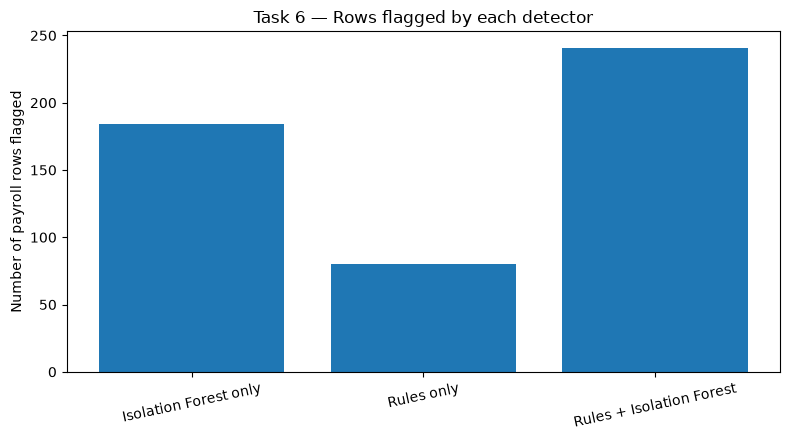

Saved: /workspace/evidence/task6_detector_flag_counts.png


,payroll_item_id,employee_id,month,gross_pay,total_deductions,net_pay,gross_vs_fixed,deduction_ratio,net_ratio,anomaly_score,model_anomaly_flag,rules_anomaly_flag,combined_anomaly_flag
5882,PI-005869,EMP-0503,2026-06-01,514200.66,688444.91,-174244.25,2.547667,1.338864,-0.338864,0.192944,1,1,1
743,PI-000741,EMP-0578,2025-05-01,27958.98,32169.86,-4210.88,1.015508,1.150609,-0.150609,0.157506,1,1,1
5568,PI-005556,EMP-0633,2026-05-01,23389.88,26785.59,-3395.71,1.062500,1.145179,-0.145179,0.154759,1,1,1
492,PI-000493,EMP-0209,2025-05-01,193442.81,237902.78,-44459.97,0.983871,1.229835,-0.229835,0.152185,1,1,1
5454,PI-005443,EMP-0469,2026-05-01,101865.00,114051.50,-12186.50,1.000000,1.119634,-0.119634,0.150545,1,1,1
6080,PI-006067,EMP-0057,2026-07-01,69857.00,78842.70,-8985.70,1.000000,1.128630,-0.128630,0.150545,1,1,1
6872,PI-006858,EMP-0690,2026-08-01,41208.00,47328.80,-6120.80,1.000000,1.148534,-0.148534,0.150545,1,1,1
3099,PI-003094,EMP-0588,2025-11-01,55709.00,63279.90,-7570.90,1.000000,1.135901,-0.135901,0.150545,1,1,1
3309,PI-003304,EMP-0304,2025-12-01,2823640.50,47789.65,2345744.00,14.330000,0.016925,0.830752,0.145167,1,1,1
2600,PI-002595,EMP-0453,2025-10-01,2424310.00,39288.47,2031425.30,10.430235,0.016206,0.837940,0.143336,1,1,1


In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(flag_counts["detector"], flag_counts["flagged_rows"])
ax.set_title("Task 6 — Rows flagged by each detector")
ax.set_ylabel("Number of payroll rows flagged")
ax.tick_params(axis="x", rotation=12)
fig.tight_layout()
FLAG_CHART_PATH = EVIDENCE_DIR / "task6_detector_flag_counts.png"
fig.savefig(FLAG_CHART_PATH, dpi=160, bbox_inches="tight")
plt.show()
print("Saved:", FLAG_CHART_PATH)

inspection_cols = [
    c for c in [
        "payroll_item_id", "employee_id", "month", "gross_pay",
        "total_deductions", "net_pay", "gross_vs_fixed", "deduction_ratio",
        "net_ratio", "anomaly_score", "model_anomaly_flag",
        "rules_anomaly_flag", "combined_anomaly_flag"
    ] if c in payroll.columns
]
display(payroll.sort_values("anomaly_score", ascending=False)[inspection_cols].head(25))


## 7. Supplied baseline reference

This development-only comparison records the metrics supplied with the project (precision 0.217, recall 0.400, 184 rows flagged, and 100 injected anomalies). The new detectors are shown with prediction counts only; their precision and recall are intentionally blank until a separate, permitted final evaluation. Do not infer that the supplied baseline and this run are directly comparable without checking their evaluation definitions.

,detector,precision,recall,flagged,actual_anomalies
0,Supplied payroll baseline,0.217,0.4,184,100.0
1,Isolation Forest only,NaN,NaN,184,NaN
2,Rules only,NaN,NaN,80,NaN
3,Rules + Isolation Forest,NaN,NaN,241,NaN


Saved: /workspace/reports/task6_baseline_comparison.csv


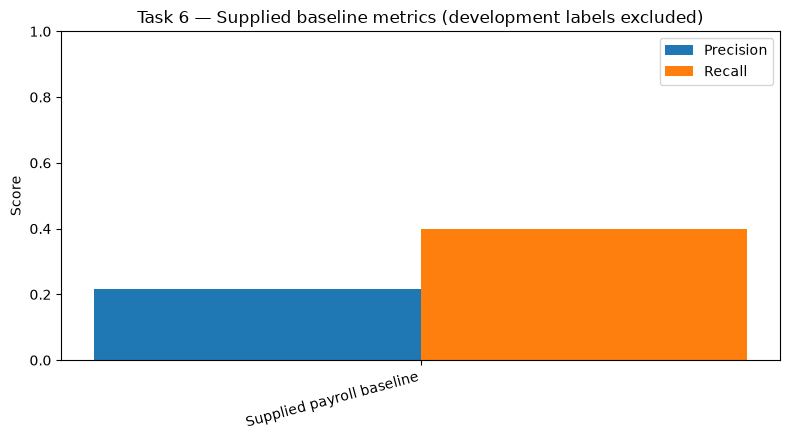

Saved: /workspace/evidence/task6_baseline_reference.png


In [8]:
# Development-only baseline summary. This cell does not use validation labels.
baseline_comparison = pd.DataFrame([{
    "detector": "Supplied payroll baseline",
    "precision": float(baseline_row["precision"]),
    "recall": float(baseline_row["recall"]),
    "flagged": int(baseline_row["flagged"]),
    "actual_anomalies": int(baseline_row["injected"])
}])

# Add prediction-only counts for the detectors developed in this notebook.
prediction_summary = flag_counts.rename(
    columns={"detector": "detector", "flagged_rows": "flagged"}
).copy()
prediction_summary["precision"] = np.nan
prediction_summary["recall"] = np.nan
prediction_summary["actual_anomalies"] = np.nan

baseline_comparison = pd.concat(
    [baseline_comparison, prediction_summary[
        ["detector", "precision", "recall", "flagged", "actual_anomalies"]
    ]],
    ignore_index=True,
    sort=False
)

BASELINE_COMPARISON_PATH = REPORTS_DIR / "task6_baseline_comparison.csv"
baseline_comparison.to_csv(BASELINE_COMPARISON_PATH, index=False)
display(baseline_comparison)
print("Saved:", BASELINE_COMPARISON_PATH)

# This chart is prediction-only; precision/recall for the new detectors remain blank
# until a separate post-completion evaluation is performed.
plot_df = baseline_comparison.dropna(subset=["precision", "recall"]).copy()
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(plot_df))
width = 0.36
ax.bar(x - width/2, plot_df["precision"], width, label="Precision")
ax.bar(x + width/2, plot_df["recall"], width, label="Recall")
ax.set_xticks(x)
ax.set_xticklabels(plot_df["detector"], rotation=15, ha="right")
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Task 6 — Supplied baseline metrics (development labels excluded)")
ax.legend()
fig.tight_layout()
METRICS_CHART_PATH = EVIDENCE_DIR / "task6_baseline_reference.png"
fig.savefig(METRICS_CHART_PATH, dpi=160, bbox_inches="tight")
plt.show()
print("Saved:", METRICS_CHART_PATH)


## 8. Task 6 development checkpoint — labels intentionally excluded

This notebook intentionally **does not load or inspect** `unlock_CX-06_payroll_anomaly_labels.csv`.

At this point, the detector development outputs have been saved:
- `reports/task6_payroll_anomaly_predictions.csv`
- `reports/task6_detector_flag_counts.csv`
- `reports/task6_rule_flag_counts.csv`
- `evidence/task6_detector_flag_counts.png`

Stop here for development. Keep the unlock file separate. When you explicitly decide to evaluate the frozen predictions, use a separate evaluation-only notebook or script that reads the saved prediction CSV and the unlock file solely to calculate metrics. Do not change the model, features, rules, or thresholds based on those evaluation results.

In [9]:
# Freeze predictions once; if a frozen snapshot already exists, verify rather than overwrite it.
import hashlib

FROZEN_PREDICTIONS_PATH = REPORTS_DIR / "task6_payroll_anomaly_predictions_frozen.csv"

if FROZEN_PREDICTIONS_PATH.exists():
    frozen_existing = pd.read_csv(FROZEN_PREDICTIONS_PATH)
    current_predictions = pd.read_csv(PREDICTIONS_PATH)
    same = frozen_existing.equals(current_predictions)
    print("Frozen snapshot already exists:", FROZEN_PREDICTIONS_PATH)
    print("Matches current predictions:", same)
    print("Frozen rows:", len(frozen_existing))
    print("SHA-256:", hashlib.sha256(FROZEN_PREDICTIONS_PATH.read_bytes()).hexdigest())
    if not same:
        print("WARNING: Existing frozen snapshot differs from current predictions. Do not overwrite it; inspect before evaluation.")
else:
    predictions.to_csv(FROZEN_PREDICTIONS_PATH, index=False)
    print("Frozen snapshot created:", FROZEN_PREDICTIONS_PATH)
    print("Frozen rows:", len(predictions))
    print("SHA-256:", hashlib.sha256(FROZEN_PREDICTIONS_PATH.read_bytes()).hexdigest())


Frozen snapshot already exists: /workspace/reports/task6_payroll_anomaly_predictions_frozen.csv
Matches current predictions: False
Frozen rows: 7355
SHA-256: 2cbc933db2938a92eef78fa20808ea6140aed315a68d657bfd01f74c4544b6f9


## 9. Next steps after the development freeze

This notebook completes detector development and saves predictions without loading hidden validation labels. Do not use hidden labels to change features, rules, model settings, or thresholds.

After confirming the task requirements and freezing the prediction CSV, use a separate evaluation-only notebook or script to compare those saved predictions with the unlock labels. That separate evaluation should report overall precision, recall, F1, false positives, missed anomalies, and results by anomaly type. Then write `reports/task6_missed_anomaly_analysis.md` using the measured results.

Development checklist:
- [ ] Payroll ratios and data checks are reviewed.
- [ ] Duplicate-payment, negative-net-pay, deductions-over-gross, and reconciliation rules are implemented.
- [ ] Isolation Forest uses visible features only.
- [ ] Predictions are saved before hidden labels are accessed.
- [ ] Model-only, rules-only, and combined detector counts are recorded.
- [ ] Baseline reference metrics are kept separate from current detector metrics.
- [ ] Limitations are documented without claiming production readiness.

Evaluation checklist (complete only in the separate evaluation step):
- [ ] Overall metrics are calculated against the authorized labels.
- [ ] Results by anomaly type and missed-anomaly analysis are produced.
- [ ] The final report documents trade-offs and limitations.


In [10]:

from pathlib import Path
import pandas as pd

reports = Path("/workspace/reports")

current = pd.read_csv(reports / "task6_payroll_anomaly_predictions.csv")
frozen = pd.read_csv(reports / "task6_payroll_anomaly_predictions_frozen.csv")

flags = [
    "model_anomaly_flag",
    "rules_anomaly_flag",
    "combined_anomaly_flag",
]

print("Current rows:", len(current))
print("Frozen rows:", len(frozen))

print("\nCurrent flag totals:")
print(current[flags].sum().to_dict())

print("\nFrozen flag totals:")
print(frozen[flags].sum().to_dict())

key = "payroll_item_id"
print("\nSame payroll IDs:",
      set(current[key]) == set(frozen[key]))

if set(current[key]) == set(frozen[key]):
    a = current.set_index(key).sort_index()
    b = frozen.set_index(key).sort_index()

    cols = sorted(set(a.columns) & set(b.columns))
    diff = a[cols].compare(b[cols])

    print("Different cells:", len(diff))
    print("Rows with differences:", diff.index.nunique())
    print("\nFirst differences:")
    print(diff.head(8).to_string())


Current rows: 7355
Frozen rows: 7355

Current flag totals:
{'model_anomaly_flag': 184, 'rules_anomaly_flag': 80, 'combined_anomaly_flag': 241}

Frozen flag totals:
{'model_anomaly_flag': 184, 'rules_anomaly_flag': 80, 'combined_anomaly_flag': 241}

Same payroll IDs: True
Different cells: 4
Rows with differences: 4

First differences:
                gross_vs_fixed           net_reconciliation_gap        
                          self     other                   self   other
payroll_item_id                                                        
PI-000061             1.852115  1.852115                    NaN     NaN
PI-005151                  NaN       NaN                -237.85 -237.85
PI-006867                  NaN       NaN                -204.12 -204.12
PI-006976             1.937000  1.937000                    NaN     NaN


In [11]:
from pathlib import Path
import pandas as pd
import numpy as np

reports = Path("/workspace/reports")

current = pd.read_csv(reports / "task6_payroll_anomaly_predictions.csv")
frozen = pd.read_csv(reports / "task6_payroll_anomaly_predictions_frozen.csv")

key = "payroll_item_id"
current = current.set_index(key).sort_index()
frozen = frozen.set_index(key).sort_index()

# Check whether all anomaly decisions match
flags = [
    "model_anomaly_flag",
    "rules_anomaly_flag",
    "combined_anomaly_flag",
]

print("All anomaly flags identical:",
      current[flags].equals(frozen[flags]))

# Compare the two numeric columns with floating-point tolerance
for col in ["gross_vs_fixed", "net_reconciliation_gap"]:
    a = current[col].to_numpy(dtype=float)
    b = frozen[col].to_numpy(dtype=float)

    print(f"\n{col}")
    print("Equal within tolerance:",
          np.allclose(a, b, rtol=1e-9, atol=1e-8, equal_nan=True))
    print("Maximum absolute difference:",
          np.nanmax(np.abs(a - b)))

All anomaly flags identical: True

gross_vs_fixed
Equal within tolerance: True
Maximum absolute difference: 4.440892098500626e-16

net_reconciliation_gap
Equal within tolerance: True
Maximum absolute difference: 2.842170943040401e-14


In [1]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Locate the project and required files
ROOT = Path("/workspace") if Path("/workspace").exists() else Path.cwd()

def locate_file(filename, preferred_dirs):
    for directory in preferred_dirs:
        path = directory / filename
        if path.is_file():
            return path

    for path in ROOT.rglob(filename):
        if ".git" not in path.parts and ".ipynb_checkpoints" not in path.parts:
            return path

    raise FileNotFoundError(
        f"Cannot find {filename}. Check its location in your project."
    )

pred_path = locate_file(
    "task6_payroll_anomaly_predictions_frozen.csv",
    [ROOT / "reports", ROOT]
)

unlock_path = locate_file(
    "unlock_CX-06_payroll_anomaly_labels.csv",
    [
        ROOT / "04_Validation_Vault",
        ROOT / "data" / "04_Validation_Vault",
        ROOT / "data",
        ROOT
    ]
)

predictions = pd.read_csv(pred_path)
labels = pd.read_csv(unlock_path)

print("Frozen predictions:", pred_path)
print("Unlock labels:", unlock_path)
print("Prediction rows:", len(predictions))
print("Label rows:", len(labels))
print("Label columns:", labels.columns.tolist())

display(labels.head())


Frozen predictions: /workspace/reports/task6_payroll_anomaly_predictions_frozen.csv
Unlock labels: /workspace/04_Validation_Vault/unlock_CX-06_payroll_anomaly_labels.csv
Prediction rows: 7355
Label rows: 100
Label columns: ['payroll_item_id', 'anomaly_type', 'field_changed', 'original_value', 'injection_note']


,payroll_item_id,anomaly_type,field_changed,original_value,injection_note
0,PI-D00001,DOUBLE_PAYMENT,row,single payment,second identical payment for same employee and...
1,PI-D00002,DOUBLE_PAYMENT,row,single payment,second identical payment for same employee and...
2,PI-D00003,DOUBLE_PAYMENT,row,single payment,second identical payment for same employee and...
3,PI-D00004,DOUBLE_PAYMENT,row,single payment,second identical payment for same employee and...
4,PI-D00005,DOUBLE_PAYMENT,row,single payment,second identical payment for same employee and...


In [2]:

# Identify label columns without guessing silently
def find_column(df, candidates):
    lookup = {str(c).strip().lower(): c for c in df.columns}
    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]
    return None

pred_id = "payroll_item_id"

label_id = find_column(
    labels,
    ["payroll_item_id", "item_id", "payroll_id", "record_id"]
)
binary_col = find_column(
    labels,
    ["actual_anomaly", "is_anomaly", "anomaly_label", "label", "target"]
)
type_col = find_column(
    labels,
    ["anomaly_type", "error_type", "label_type", "type"]
)

if pred_id not in predictions.columns or label_id is None:
    raise ValueError(
        "Could not identify the payroll ID columns. "
        f"Prediction columns: {predictions.columns.tolist()}; "
        f"label columns: {labels.columns.tolist()}"
    )

if not predictions[pred_id].is_unique:
    raise ValueError("Frozen predictions contain duplicate payroll IDs.")

if not labels[label_id].is_unique:
    raise ValueError("Unlock labels contain duplicate IDs.")

if type_col is None:
    raise ValueError(
        "Could not identify the anomaly-type column. "
        "Inspect the label columns printed in Cell 1."
    )

label_data = labels[[label_id, type_col] +
                    ([binary_col] if binary_col else [])].copy()

label_data = label_data.rename(columns={
    label_id: pred_id,
    type_col: "anomaly_type"
})

if binary_col:
    label_data = label_data.rename(
        columns={binary_col: "actual_anomaly"}
    )

prediction_ids = set(predictions[pred_id])
label_ids = set(label_data[pred_id])

if not label_ids.issubset(prediction_ids):
    raise ValueError(
        f"{len(label_ids - prediction_ids)} label IDs do not exist "
        "in the frozen predictions. Stop and inspect the IDs."
    )

# Merge labels onto the frozen predictions
evaluation = predictions.merge(
    label_data,
    on=pred_id,
    how="left",
    validate="one_to_one",
    indicator=True
)

if binary_col:
    # Full labels or a binary-labelled positive-only list
    evaluation["actual_anomaly"] = pd.to_numeric(
        evaluation["actual_anomaly"], errors="raise"
    ).fillna(0).astype(int)
else:
    # If no binary column exists, infer positives from labelled types.
    # This is valid only if the unlock file lists anomalies only,
    # or provides anomaly types only for actual anomalies.
    evaluation["actual_anomaly"] = (
        evaluation["_merge"].eq("both")
        & evaluation["anomaly_type"].notna()
    ).astype(int)

evaluation = evaluation.drop(columns="_merge")

if not set(evaluation["actual_anomaly"].unique()).issubset({0, 1}):
    raise ValueError("Actual anomaly labels must be binary 0/1.")

flag_columns = {
    "Isolation Forest only": "model_anomaly_flag",
    "Rules only": "rules_anomaly_flag",
    "Rules + Isolation Forest": "combined_anomaly_flag"
}

for col in flag_columns.values():
    if col not in evaluation.columns:
        raise ValueError(f"Missing prediction column: {col}")

    evaluation[col] = pd.to_numeric(
        evaluation[col], errors="raise"
    ).astype(int)

    if not set(evaluation[col].unique()).issubset({0, 1}):
        raise ValueError(f"{col} must contain only 0 and 1.")

actual_count = int(evaluation["actual_anomaly"].sum())

print("Rows evaluated:", len(evaluation))
print("Actual anomalies identified:", actual_count)
print("Labelled anomaly types:")
print(
    evaluation.loc[
        evaluation["actual_anomaly"] == 1, "anomaly_type"
    ].value_counts(dropna=False)
)

if actual_count == 0:
    raise ValueError(
        "No actual anomalies were identified. Stop and inspect the "
        "unlock file schema; do not trust the metrics."
    )


Rows evaluated: 7355
Actual anomalies identified: 100
Labelled anomaly types:
anomaly_type
OVERTIME_SPIKE      15
MISSED_DEDUCTION    15
ROLE_MISMATCH       15
DOUBLE_PAYMENT      15
WRONG_DECIMAL       15
STALE_SALARY        12
NEGATIVE_NET         8
ZERO_PAY             5
Name: count, dtype: int64


In [3]:

def calculate_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)

    tp = int(((y_true == 1) & (y_pred == 1)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    tn = int(((y_true == 0) & (y_pred == 0)).sum())

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    return {
        "total_rows": len(y_true),
        "actual_anomalies": int(y_true.sum()),
        "flagged": int(y_pred.sum()),
        "caught": tp,
        "false_positives": fp,
        "missed": fn,
        "true_negatives": tn,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

overall_rows = []

for detector, flag in flag_columns.items():
    result = calculate_metrics(
        evaluation["actual_anomaly"],
        evaluation[flag]
    )
    result["detector"] = detector
    overall_rows.append(result)

overall_metrics = pd.DataFrame(overall_rows)

display(overall_metrics.round(4))

reports_dir = ROOT / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

overall_metrics.to_csv(
    reports_dir / "task6_overall_detector_comparison.csv",
    index=False
)

print("Saved overall detector metrics.")


,total_rows,actual_anomalies,flagged,caught,false_positives,missed,true_negatives,precision,recall,f1,detector
0,7355,100,184,37,147,63,7108,0.2011,0.37,0.2606,Isolation Forest only
1,7355,100,80,65,15,35,7240,0.8125,0.65,0.7222,Rules only
2,7355,100,241,79,162,21,7093,0.3278,0.79,0.4633,Rules + Isolation Forest


Saved overall detector metrics.


In [4]:

# Evaluate each labelled anomaly type for all three detectors
positive = evaluation[evaluation["actual_anomaly"] == 1].copy()

per_type_rows = []

for detector, flag in flag_columns.items():
    total_flagged = int(evaluation[flag].sum())

    for anomaly_type, group in positive.groupby(
        "anomaly_type", dropna=False
    ):
        actual_n = len(group)
        caught_n = int(group[flag].sum())

        per_type_rows.append({
            "detector": detector,
            "anomaly_type": str(anomaly_type),
            "actual_rows_of_type": actual_n,
            "caught_rows_of_type": caught_n,
            "missed_rows_of_type": actual_n - caught_n,
            "type_precision_contribution": (
                caught_n / total_flagged if total_flagged else 0.0
            ),
            "type_recall": (
                caught_n / actual_n if actual_n else 0.0
            )
        })

per_type_metrics = pd.DataFrame(per_type_rows)

display(per_type_metrics.round(4))

per_type_metrics.to_csv(
    reports_dir / "task6_per_error_type_metrics.csv",
    index=False
)

# Combined detector's missed anomalies
combined_flag = flag_columns["Rules + Isolation Forest"]

missed = evaluation[
    (evaluation["actual_anomaly"] == 1)
    & (evaluation[combined_flag] == 0)
].copy()

missed.to_csv(
    reports_dir / "task6_missed_anomaly_analysis.csv",
    index=False
)

missed_types = (
    missed.groupby("anomaly_type", dropna=False)
    .size()
    .rename("missed_rows")
    .reset_index()
    .sort_values("missed_rows", ascending=False)
)

missed_types.to_csv(
    reports_dir / "task6_missed_anomaly_types.csv",
    index=False
)

# Actual anomalies caught by rules but missed by Isolation Forest
rules_caught_model_missed = evaluation[
    (evaluation["actual_anomaly"] == 1)
    & (evaluation["rules_anomaly_flag"] == 1)
    & (evaluation["model_anomaly_flag"] == 0)
]

rules_missed_summary = (
    rules_caught_model_missed.groupby("anomaly_type", dropna=False)
    .size()
    .rename("rows_rules_caught_model_missed")
    .reset_index()
    .sort_values("rows_rules_caught_model_missed", ascending=False)
)

rules_missed_summary.to_csv(
    reports_dir / "task6_rules_caught_model_missed.csv",
    index=False
)

print("Combined detector missed:", len(missed))
print("\nMissed anomaly types:")
display(missed_types)

print("\nRules caught, model missed:")
display(rules_missed_summary)

print("\nSaved the per-type and missed-anomaly reports.")


,detector,anomaly_type,actual_rows_of_type,caught_rows_of_type,missed_rows_of_type,type_precision_contribution,type_recall
0,Isolation Forest only,DOUBLE_PAYMENT,15,0,15,0.0000,0.0000
1,Isolation Forest only,MISSED_DEDUCTION,15,1,14,0.0054,0.0667
2,Isolation Forest only,NEGATIVE_NET,8,8,0,0.0435,1.0000
3,Isolation Forest only,OVERTIME_SPIKE,15,13,2,0.0707,0.8667
4,Isolation Forest only,ROLE_MISMATCH,15,0,15,0.0000,0.0000
5,Isolation Forest only,STALE_SALARY,12,0,12,0.0000,0.0000
6,Isolation Forest only,WRONG_DECIMAL,15,15,0,0.0815,1.0000
7,Isolation Forest only,ZERO_PAY,5,0,5,0.0000,0.0000
8,Rules only,DOUBLE_PAYMENT,15,15,0,0.1875,1.0000
9,Rules only,MISSED_DEDUCTION,15,0,15,0.0000,0.0000


Combined detector missed: 21

Missed anomaly types:


,anomaly_type,missed_rows
0,MISSED_DEDUCTION,14
2,ZERO_PAY,5
1,OVERTIME_SPIKE,2



Rules caught, model missed:


,anomaly_type,rows_rules_caught_model_missed
0,DOUBLE_PAYMENT,15
1,ROLE_MISMATCH,15
2,STALE_SALARY,12



Saved the per-type and missed-anomaly reports.


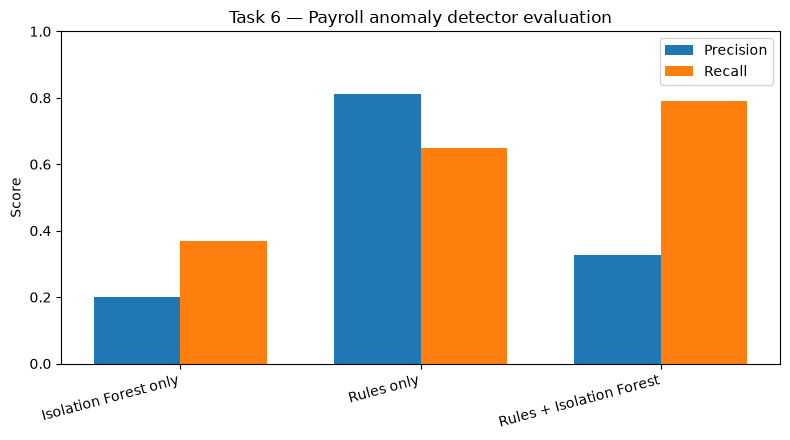

Saved evidence/task6_evaluation_metrics.png


In [5]:

fig, ax = plt.subplots(figsize=(8, 4.5))

x = np.arange(len(overall_metrics))
width = 0.36

ax.bar(
    x - width / 2,
    overall_metrics["precision"],
    width,
    label="Precision"
)
ax.bar(
    x + width / 2,
    overall_metrics["recall"],
    width,
    label="Recall"
)

ax.set_xticks(x)
ax.set_xticklabels(
    overall_metrics["detector"],
    rotation=15,
    ha="right"
)
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Task 6 — Payroll anomaly detector evaluation")
ax.legend()
fig.tight_layout()

evidence_dir = ROOT / "evidence"
evidence_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    evidence_dir / "task6_evaluation_metrics.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

print("Saved evidence/task6_evaluation_metrics.png")


In [7]:
pip install tabulate


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [8]:

report_lines = [
    "# Task 6 — Payroll Anomaly Detector Evaluation",
    "",
    "## Overall results",
    "",
    overall_metrics[
        ["detector", "flagged", "caught", "false_positives",
         "missed", "precision", "recall", "f1"]
    ].round(4).to_markdown(index=False),
    "",
    "## Results by anomaly type",
    "",
    per_type_metrics.round(4).to_markdown(index=False),
    "",
    "## Missed anomalies — combined detector",
    "",
    missed_types.to_markdown(index=False),
    "",
    "## Rules caught, Isolation Forest missed",
    "",
    rules_missed_summary.to_markdown(index=False),
    "",
    "## Interpretation and limitations",
    "",
    "- The detector predictions were frozen before this evaluation.",
    "- Unlock labels were used only to calculate evaluation metrics.",
    "- Evaluation results were not used to retrain or tune the detector.",
    "- Precision measures how many flagged records were actual anomalies.",
    "- Recall measures how many actual anomalies were detected.",
    "- False positives and missed anomalies represent different operational trade-offs.",
    "- These results alone do not establish production readiness.",
]

report_path = reports_dir / "task6_missed_anomaly_analysis.md"
report_path.write_text("\n".join(report_lines), encoding="utf-8")

print("Saved:", report_path)


Saved: /workspace/reports/task6_missed_anomaly_analysis.md
